# Kathmandu US AQI: Preprocessing and Post-Preprocessing Exploration
Group E "Los Lobos" | CSC61304 | Track 10: Air Quality Monitoring

**Task (locked):** predict `us_aqi` from weather and time only. No pollutant columns, no past AQI.

**What this notebook does (no model is fitted here):**
1. Add the wind columns from `kathmandu_final.csv` into `kathmandu_weather.csv`
2. Cut the time range to Oct 2022 to Sep 2026 (four full October-to-September years)
3. Run cleaning checks
4. Build the sine/cosine features for hour and month
5. Split chronologically (train: first 3 years, test: last year)
6. Drop `time` and the plain `hour` / `month`, so only the feature list reaches the model
7. Explore the preprocessed data (train only, so the test year stays unseen)

Decisions and reasons are in `kathmandu_aqi_decisions_and_pipeline.md`.

## 0. Setup and settings

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

# ---- file locations (change DATA_DIR if the CSVs are in another folder) ----
DATA_DIR = Path('.')
FINAL_CSV = DATA_DIR / 'kathmandu_final.csv'
WEATHER_CSV = DATA_DIR / 'kathmandu_weather.csv'
WEATHER_BACKUP = DATA_DIR / 'kathmandu_weather_backup.csv'   # copy of the weather file before wind is added
PROCESSED_CSV = DATA_DIR / 'kathmandu_processed.csv'         # trimmed + engineered, all rows
TRAIN_CSV = DATA_DIR / 'kathmandu_train.csv'
TEST_CSV = DATA_DIR / 'kathmandu_test.csv'

# ---- decisions ----
TARGET = 'us_aqi'
START = pd.Timestamp('2022-10-01 00:00')       # first hour kept
END = pd.Timestamp('2026-09-30 23:00')         # last hour kept
TEST_START = pd.Timestamp('2025-10-01 00:00')  # test = last year
WIND_COLS = ['wind_speed_10m', 'wind_gusts_10m', 'wind_direction_10m']
INCLUDE_WIND = False   # decision D6: wind dropped. Set True only if you want wind as inputs.

BASE_FEATURES = ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation',
                 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']
FEATURES = BASE_FEATURES + (WIND_COLS if INCLUDE_WIND else [])
print('Features going to the model:', FEATURES)

Features going to the model: ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']


## 1. Add the wind columns to the weather file
`kathmandu_final.csv` has everything. `kathmandu_weather.csv` is the weather-only subset and has no wind.
We take the three wind columns from the final file and attach them by matching on `time`, so rows cannot get mixed up.
A backup of the original weather file is made the first time this runs.

In [2]:
final = pd.read_csv(FINAL_CSV, parse_dates=['time'])
weather = pd.read_csv(WEATHER_CSV, parse_dates=['time'])
print('final  :', final.shape)
print('weather:', weather.shape)

if not WEATHER_BACKUP.exists():
    weather.to_csv(WEATHER_BACKUP, index=False)
    print('Backup saved:', WEATHER_BACKUP)

final  : (36427, 24)
weather: (36427, 15)
Backup saved: kathmandu_weather_backup.csv


In [3]:
# remove old wind columns if the notebook is re-run, then attach them fresh from the final file
weather = weather.drop(columns=[c for c in WIND_COLS if c in weather.columns])
weather = weather.merge(final[['time'] + WIND_COLS], on='time', how='left', validate='one_to_one')

# safety checks: nothing missing, same number of rows, target matches the final file
assert len(weather) == len(final), 'row count changed during merge'
assert weather[WIND_COLS].isna().sum().sum() == 0, 'some hours have no wind value'
check = weather[['time', TARGET]].merge(final[['time', TARGET]], on='time', suffixes=('', '_final'))
assert np.allclose(check[TARGET], check[TARGET + '_final']), 'target differs between files'

weather.to_csv(WEATHER_CSV, index=False)
print('Saved', WEATHER_CSV, 'with shape', weather.shape)
print(list(weather.columns))

Saved kathmandu_weather.csv with shape (36427, 18)
['time', 'temperature_2m', 'dew_point_2m', 'apparent_temperature', 'relative_humidity_2m', 'cloud_cover', 'weather_code', 'rain', 'precipitation', 'surface_pressure', 'shortwave_radiation', 'uv_index', 'hour', 'month', 'us_aqi', 'wind_speed_10m', 'wind_gusts_10m', 'wind_direction_10m']


## 2. Cut the time range
Keep **2022-10-01 00:00 to 2026-09-30 23:00**. That gives four complete October-to-September years, each with one full set of seasons.
Expected rows: (365 + 366 + 365 + 365) days x 24 hours = **35,064** (2024 is a leap year).

In [4]:
df = weather[(weather['time'] >= START) & (weather['time'] <= END)].copy()
df = df.sort_values('time').reset_index(drop=True)

expected_times = pd.date_range(START, END, freq='h')
print('rows kept    :', len(df))
print('rows expected:', len(expected_times))
print('first / last :', df['time'].min(), '/', df['time'].max())
print('rows dropped :', len(weather) - len(df))

# if there are no duplicates and the count matches, there are no gaps
assert len(df) == len(expected_times), 'row count differs from expected'
assert (df['time'].values == expected_times.values).all(), 'there are gaps or duplicated hours'
print('Hourly series is complete: no gaps, no duplicates.')

rows kept    : 35064
rows expected: 35064
first / last : 2022-10-01 00:00:00 / 2026-09-30 23:00:00
rows dropped : 1363
Hourly series is complete: no gaps, no duplicates.


## 3. Cleaning checks
Light job: no nulls were found earlier, so these are checks, not repairs.
Pollution spikes are **kept** because they are real days, and removing them would hide the exact events the model should learn.

In [5]:
print('Missing values (total):', int(df.isna().sum().sum()))
print('Duplicate timestamps  :', int(df['time'].duplicated().sum()))

rules = {
    'relative_humidity_2m between 0 and 100': ((df['relative_humidity_2m'] < 0) | (df['relative_humidity_2m'] > 100)),
    'cloud_cover between 0 and 100':          ((df['cloud_cover'] < 0) | (df['cloud_cover'] > 100)),
    'precipitation >= 0':                     (df['precipitation'] < 0),
    'rain >= 0':                              (df['rain'] < 0),
    'wind_speed_10m >= 0':                    (df['wind_speed_10m'] < 0),
    'wind_gusts_10m >= 0':                    (df['wind_gusts_10m'] < 0),
    'wind_direction_10m between 0 and 360':   ((df['wind_direction_10m'] < 0) | (df['wind_direction_10m'] > 360)),
    'us_aqi between 0 and 500':               ((df[TARGET] < 0) | (df[TARGET] > 500)),
}
for name, bad in rules.items():
    print(f'{name:42s} rows breaking the rule: {int(bad.sum())}')

print('\nrain identical to precipitation on every row:', bool((df['rain'] == df['precipitation']).all()))

Missing values (total): 0
Duplicate timestamps  : 0
relative_humidity_2m between 0 and 100     rows breaking the rule: 0
cloud_cover between 0 and 100              rows breaking the rule: 0
precipitation >= 0                         rows breaking the rule: 0
rain >= 0                                  rows breaking the rule: 0
wind_speed_10m >= 0                        rows breaking the rule: 0
wind_gusts_10m >= 0                        rows breaking the rule: 0
wind_direction_10m between 0 and 360       rows breaking the rule: 0
us_aqi between 0 and 500                   rows breaking the rule: 0

rain identical to precipitation on every row: True


In [6]:
# outliers: look at the worst hours instead of deleting them
df.nlargest(5, TARGET)[['time', TARGET, 'dew_point_2m', 'cloud_cover', 'precipitation']]

,time,us_aqi,dew_point_2m,cloud_cover,precipitation
30210,2026-03-12 18:00:00,217.0,14.9,69,0.0
30211,2026-03-12 19:00:00,217.0,14.5,89,0.0
30212,2026-03-12 20:00:00,217.0,14.6,77,0.0
30213,2026-03-12 21:00:00,217.0,14.4,60,0.0
30206,2026-03-12 14:00:00,216.0,14.8,98,1.0


## 4. Feature engineering: sine and cosine for hour and month
Plain numbers say hour 23 and hour 0 are 23 steps apart, and month 12 and month 1 are 11 steps apart, although they are neighbours.
A sine/cosine pair puts each time on a circle, so the day and the year wrap around.

```
month_sin = sin(2 pi x month / 12)     month_cos = cos(2 pi x month / 12)
hour_sin  = sin(2 pi x hour / 24)      hour_cos  = cos(2 pi x hour / 24)
```
`hour` and `month` are created first as helper columns, then replaced by the pairs before fitting.

In [7]:
df['hour'] = df['time'].dt.hour
df['month'] = df['time'].dt.month

df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

df[['time', 'hour', 'hour_sin', 'hour_cos', 'month', 'month_sin', 'month_cos']].sample(6, random_state=1)

,time,hour,hour_sin,hour_cos,month,month_sin,month_cos
11088,2024-01-06 00:00:00,0,0.000000,1.000000,1,5.000000e-01,8.660254e-01
26741,2025-10-19 05:00:00,5,0.965926,0.258819,10,-8.660254e-01,5.000000e-01
10243,2023-12-01 19:00:00,19,-0.965926,0.258819,12,-2.449294e-16,1.000000e+00
33295,2026-07-19 07:00:00,7,0.965926,-0.258819,7,-5.000000e-01,-8.660254e-01
10468,2023-12-11 04:00:00,4,0.866025,0.500000,12,-2.449294e-16,1.000000e+00
12856,2024-03-19 16:00:00,16,-0.866025,-0.500000,3,1.000000e+00,6.123234e-17


distance Dec to Jan       : 0.52
distance Jan to Jul       : 2.0
distance hour 23 to hour 0 : 0.26
distance hour 0 to hour 12 : 2.0


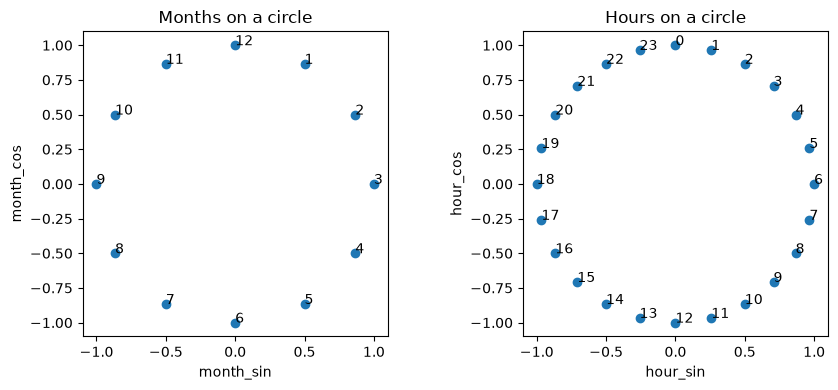

In [8]:
# check the encoding: December should be close to January, and far from July
def month_point(m):
    return np.array([np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)])

def hour_point(h):
    return np.array([np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)])

print('distance Dec to Jan       :', round(float(np.linalg.norm(month_point(12) - month_point(1))), 2))
print('distance Jan to Jul       :', round(float(np.linalg.norm(month_point(1) - month_point(7))), 2))
print('distance hour 23 to hour 0 :', round(float(np.linalg.norm(hour_point(23) - hour_point(0))), 2))
print('distance hour 0 to hour 12 :', round(float(np.linalg.norm(hour_point(0) - hour_point(12))), 2))

# picture of the two circles
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
mm = np.arange(1, 13)
axes[0].scatter(np.sin(2 * np.pi * mm / 12), np.cos(2 * np.pi * mm / 12))
for m in mm:
    axes[0].annotate(str(m), (np.sin(2 * np.pi * m / 12), np.cos(2 * np.pi * m / 12)))
axes[0].set_title('Months on a circle'); axes[0].set_xlabel('month_sin'); axes[0].set_ylabel('month_cos'); axes[0].set_aspect('equal')
hh = np.arange(24)
axes[1].scatter(np.sin(2 * np.pi * hh / 24), np.cos(2 * np.pi * hh / 24))
for h in hh:
    axes[1].annotate(str(h), (np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)))
axes[1].set_title('Hours on a circle'); axes[1].set_xlabel('hour_sin'); axes[1].set_ylabel('hour_cos'); axes[1].set_aspect('equal')
plt.tight_layout(); plt.show()

In [9]:
df.to_csv(PROCESSED_CSV, index=False)
print('Saved', PROCESSED_CSV, df.shape)

Saved kathmandu_processed.csv (35064, 22)


## 5. Chronological split
Random splitting is not used: neighbouring hours are near-copies, so a random split would put almost identical rows in both train and test and inflate the score.

- **Train:** 2022-10-01 to 2025-09-30 (three years, expected 26,304 rows)
- **Test:** 2025-10-01 to 2026-09-30 (one year, expected 8,760 rows)

Caveat for the report: the test year is dirtier on average than the first two training years, and a random forest cannot predict values beyond what it saw in training, so scores may drop.

In [10]:
train = df[df['time'] < TEST_START].copy()
test = df[df['time'] >= TEST_START].copy()

for name, part in [('train', train), ('test', test)]:
    print(f"{name:5s} rows: {len(part):6d} | {part['time'].min()} to {part['time'].max()} | mean {TARGET}: {part[TARGET].mean():.1f}")

assert len(train) == 26304 and len(test) == 8760, 'unexpected split sizes'
assert train['time'].max() < test['time'].min(), 'train and test overlap in time'

train.to_csv(TRAIN_CSV, index=False)
test.to_csv(TEST_CSV, index=False)
print('Saved', TRAIN_CSV, 'and', TEST_CSV, '(these keep time so teammates can choose their own features)')

train rows:  26304 | 2022-10-01 00:00:00 to 2025-09-30 23:00:00 | mean us_aqi: 102.2
test  rows:   8760 | 2025-10-01 00:00:00 to 2026-09-30 23:00:00 | mean us_aqi: 115.3
Saved kathmandu_train.csv and kathmandu_test.csv (these keep time so teammates can choose their own features)


## 6. Drop `time`, plain `hour` and `month`, and build X and y
Dropping `time` before fitting matters: the test year is made of dates the model never saw, so a timestamp column can only help it memorise the training years.
Hour and month are already carried by the sine/cosine pairs, so the plain versions go too.
Selecting only `FEATURES` also leaves out everything else (pollutants, `rain`, `apparent_temperature`, humidity, weather code, UV, shortwave, and wind unless `INCLUDE_WIND` is True).

In [11]:
X_train, y_train = train[FEATURES].copy(), train[TARGET].copy()
X_test, y_test = test[FEATURES].copy(), test[TARGET].copy()

# nothing that should be gone is still in X
forbidden = {'time', 'hour', 'month', TARGET, 'rain', 'apparent_temperature', 'relative_humidity_2m',
             'weather_code', 'uv_index', 'shortwave_radiation', 'surface_pressure'}
assert forbidden.isdisjoint(X_train.columns), 'a dropped column is still in X'
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

print('X_train:', X_train.shape, ' y_train:', y_train.shape)
print('X_test :', X_test.shape,  ' y_test :', y_test.shape)
print('Columns :', list(X_train.columns))

X_train: (26304, 8)  y_train: (26304,)
X_test : (8760, 8)  y_test : (8760,)
Columns : ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']


## 7. Exploration after preprocessing (train data only)
Everything below uses the **training years only**, so the test year stays unseen and nothing about it influences choices.
Scaling is not applied here: trees do not need it, and the scaling decision is still open. If the group uses it, fit the scaler on train only.

In [12]:
# 7.1 summary of the model inputs
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_2m,26304.0,1.816906e+01,5.788889,0.8,14.000000,1.920000e+01,22.200000,31.7
dew_point_2m,26304.0,1.301026e+01,6.596971,-6.7,7.400000,1.290000e+01,19.800000,23.2
cloud_cover,26304.0,4.779954e+01,42.105011,0.0,2.000000,3.900000e+01,99.000000,100.0
precipitation,26304.0,2.594434e-01,1.141840,0.0,0.000000,0.000000e+00,0.000000,24.3
month_sin,26304.0,-4.586021e-03,0.705814,-1.0,-0.866025,-2.449294e-16,0.500000,1.0
month_cos,26304.0,-1.914303e-03,0.708407,-1.0,-0.866025,-1.836970e-16,0.866025,1.0
hour_sin,26304.0,-1.701802e-17,0.707120,-1.0,-0.707107,6.123234e-17,0.707107,1.0
hour_cos,26304.0,-5.672672e-17,0.707120,-1.0,-0.707107,-6.123234e-17,0.707107,1.0


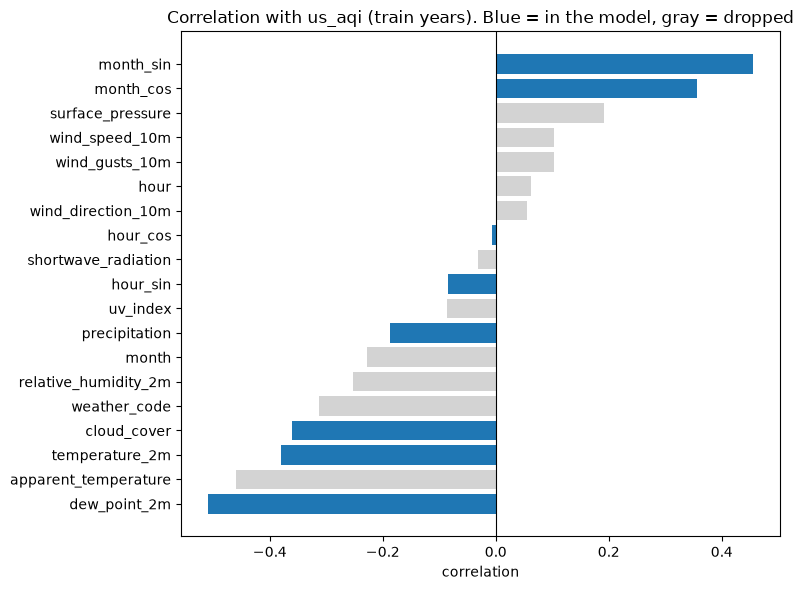

dew_point_2m           -0.509
apparent_temperature   -0.459
temperature_2m         -0.380
cloud_cover            -0.361
weather_code           -0.313
relative_humidity_2m   -0.253
month                  -0.228
precipitation          -0.187
uv_index               -0.085
hour_sin               -0.084
shortwave_radiation    -0.031
hour_cos               -0.006
wind_direction_10m      0.055
hour                    0.062
wind_gusts_10m          0.103
wind_speed_10m          0.103
surface_pressure        0.192
month_cos               0.357
month_sin               0.455
Name: us_aqi, dtype: float64

In [13]:
# 7.2 correlation with the target: the chosen features AND the columns we dropped, for comparison
candidates = FEATURES + ['hour', 'month', 'relative_humidity_2m', 'apparent_temperature', 'weather_code',
                         'uv_index', 'shortwave_radiation', 'surface_pressure'] \
             + [c for c in WIND_COLS if c not in FEATURES]
corr = train[candidates + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

colors = ['tab:blue' if c in FEATURES else 'lightgray' for c in corr.index]
plt.figure(figsize=(8, 6))
plt.barh(corr.index, corr.values, color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation with us_aqi (train years). Blue = in the model, gray = dropped')
plt.xlabel('correlation'); plt.tight_layout(); plt.show()
corr.round(3)

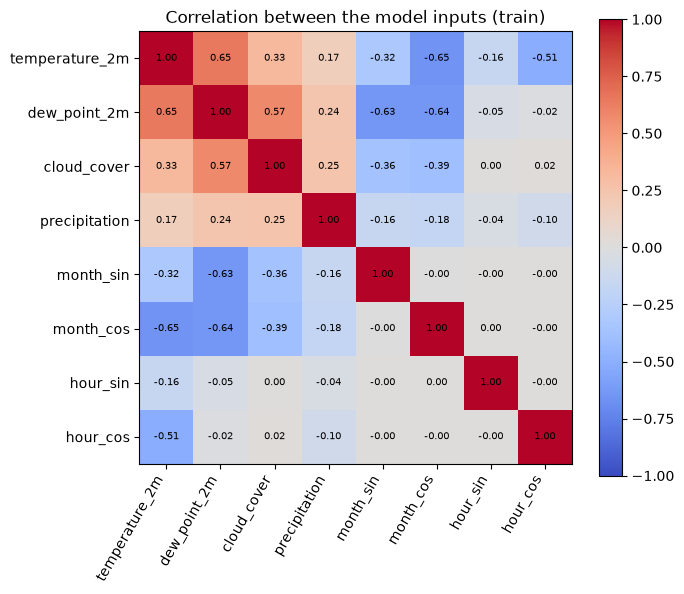

temperature vs dew point: 0.65


In [14]:
# 7.3 do the inputs overlap with each other? (heatmap)
cm = X_train.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm.values, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(cm))); ax.set_xticklabels(cm.columns, rotation=60, ha='right')
ax.set_yticks(range(len(cm))); ax.set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)):
        ax.text(j, i, f'{cm.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.title('Correlation between the model inputs (train)'); plt.tight_layout(); plt.show()
print('temperature vs dew point:', round(float(cm.loc['temperature_2m', 'dew_point_2m']), 2))

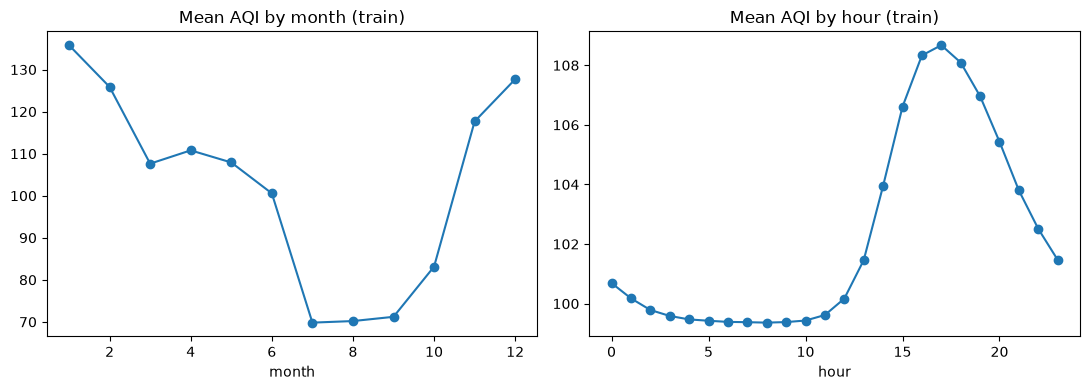

In [15]:
# 7.4 average AQI by month and by hour (train years)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
train.groupby('month')[TARGET].mean().plot(ax=axes[0], marker='o'); axes[0].set_title('Mean AQI by month (train)'); axes[0].set_xlabel('month')
train.groupby('hour')[TARGET].mean().plot(ax=axes[1], marker='o'); axes[1].set_title('Mean AQI by hour (train)'); axes[1].set_xlabel('hour')
plt.tight_layout(); plt.show()

                     count   mean   std
Oct 2022 - Sep 2023   8760  100.2  33.7
Oct 2023 - Sep 2024   8784   88.2  27.8
Oct 2024 - Sep 2025   8760  118.3  37.3
Oct 2025 - Sep 2026   8760  115.3  37.7


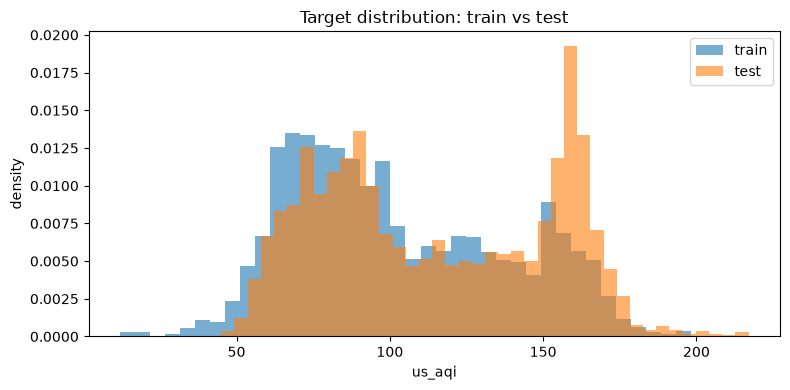

In [16]:
# 7.5 is the test year different from the training years?
df['aqi_year'] = np.where(df['month'] >= 10, df['time'].dt.year, df['time'].dt.year - 1)
block = df.groupby('aqi_year')[TARGET].agg(['count', 'mean', 'std']).round(1)
block.index = [f'Oct {y} - Sep {y + 1}' for y in block.index]
print(block)

plt.figure(figsize=(8, 4))
plt.hist(train[TARGET], bins=40, alpha=0.6, density=True, label='train')
plt.hist(test[TARGET], bins=40, alpha=0.6, density=True, label='test')
plt.xlabel(TARGET); plt.ylabel('density'); plt.legend(); plt.title('Target distribution: train vs test')
plt.tight_layout(); plt.show()

In [17]:
# 7.6 AQI bands in train and test (share of hours)
bins = [0, 50, 100, 150, 200, 300, 500]
labels = ['Good', 'Moderate', 'Sensitive', 'Unhealthy', 'Very unhealthy', 'Hazardous']
band_share = pd.DataFrame({
    'train %': pd.cut(train[TARGET], bins=bins, labels=labels).value_counts(normalize=True).sort_index() * 100,
    'test %':  pd.cut(test[TARGET],  bins=bins, labels=labels).value_counts(normalize=True).sort_index() * 100,
}).round(1)
band_share

,train %,test %
us_aqi,,
Good,2.3,0.2
Moderate,54.1,44.7
Sensitive,28.7,26.4
Unhealthy,14.9,28.3
Very unhealthy,0.0,0.4
Hazardous,0.0,0.0


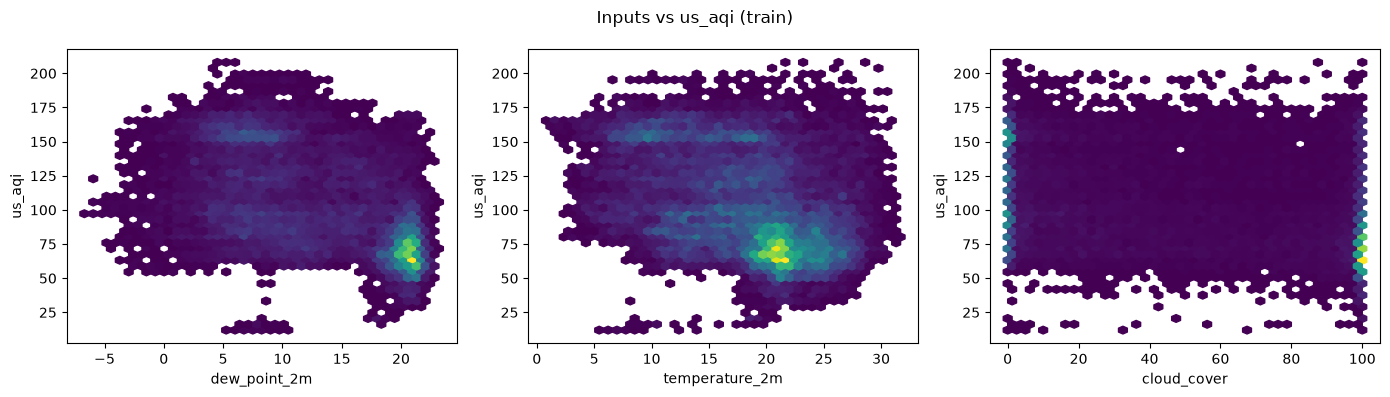

In [18]:
# 7.7 dew point, temperature and cloud cover versus AQI (train)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ['dew_point_2m', 'temperature_2m', 'cloud_cover']):
    ax.hexbin(train[col], train[TARGET], gridsize=40, cmap='viridis', mincnt=1)
    ax.set_xlabel(col); ax.set_ylabel(TARGET)
plt.suptitle('Inputs vs us_aqi (train)'); plt.tight_layout(); plt.show()

In [19]:
# 7.8 precipitation: does rain clean the air? (hours with vs without precipitation)
train.assign(raining=train['precipitation'] > 0).groupby('raining')[TARGET].agg(['count', 'mean']).round(1)

,count,mean
raining,,
False,20171,108.0
True,6133,83.2


In [20]:
# 7.9 wind check for the report: does wind add anything? (mean AQI by wind speed fifth, train)
wind_groups = pd.qcut(train['wind_speed_10m'], 5, duplicates='drop')
print(train.groupby(wind_groups, observed=True)[TARGET].mean().round(1))
print('\ncorrelations with us_aqi (train):')
print(train[WIND_COLS + [TARGET]].corr()[TARGET].drop(TARGET).round(3))

wind_speed_10m
(-0.001, 2.3]     99.9
(2.3, 3.3]        99.8
(3.3, 4.5]       100.2
(4.5, 6.2]       102.1
(6.2, 21.1]      109.6
Name: us_aqi, dtype: float64

correlations with us_aqi (train):
wind_speed_10m        0.103
wind_gusts_10m        0.103
wind_direction_10m    0.055
Name: us_aqi, dtype: float64


## 8. Ready-to-fit checkpoint
This is where modelling starts. Still open before training: scaling, model choice and baseline, Isolation Forest role, metrics, tuning method.

In [21]:
print('Target            :', TARGET)
print('Features (', len(FEATURES), ')    :', FEATURES)
print('Train             :', X_train.shape, '|', train['time'].min().date(), 'to', train['time'].max().date())
print('Test              :', X_test.shape, '|', test['time'].min().date(), 'to', test['time'].max().date())
print('time column in X? :', 'time' in X_train.columns)
print('Nulls in X / y    :', int(X_train.isna().sum().sum() + X_test.isna().sum().sum()), '/', int(y_train.isna().sum() + y_test.isna().sum()))

Target            : us_aqi
Features ( 8 )    : ['temperature_2m', 'dew_point_2m', 'cloud_cover', 'precipitation', 'month_sin', 'month_cos', 'hour_sin', 'hour_cos']
Train             : (26304, 8) | 2022-10-01 to 2025-09-30
Test              : (8760, 8) | 2025-10-01 to 2026-09-30
time column in X? : False
Nulls in X / y    : 0 / 0
